In [5]:
# Imports
import os
import sys
sys.path.append(os.path.abspath(".."))   # one level up
import numpy as np
import cv2
import open3d as o3d
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation
from utils.lidar import PointCloud
from utils.camera import ImageData
import utils.utils as utils
from natsort import natsorted

cmap = plt.get_cmap("jet")

# Toggle the following boolean to False if not using HuggingFace App
hf_app = False

if hf_app:
    from huggingface_hub import snapshot_download


In [6]:
# User parameters
location = 'Cambogan'
sequence = '20250811_113017'
condition = 'flooded'
camera_pos = 'front'
# root_directory = f"/data/FRED/{condition}/KITTI-style"
root_directory = f"C:/Users/conno/Documents/data/FRED/{condition}/KITTI-style/"


if (not os.path.exists(root_directory)) and (hf_app):
    snapshot_download(
        repo_id="CMalone-Jupiter/FRED",
        repo_type="dataset",
        local_dir="/data/FRED",
        allow_patterns=f"{condition}/KITTI-style/{location}_{sequence}/**",
        token=os.environ.get("HF_TOKEN")
    )

############ Define filenames and directories ####################################

image_dir = f"{root_directory}/{location}_{sequence}/{camera_pos}-imgs/"
lidar_dir = f"{root_directory}/{location}_{sequence}/ouster/"
utm_dir = f"{root_directory}/{location}_{sequence}/utm/"

img_calib_file = f"../camera_calib.txt"
lidar_calib_file = f"../calib.txt"

timestamps = [filename.split('.png')[0] for filename in natsorted(os.listdir(image_dir)) if os.path.isfile(image_dir+filename)]

timestamp_idx = 183
image_timestamp = timestamps[timestamp_idx]

image_filename = f"{image_dir}/{image_timestamp}.png"

lidar_filename, utm_filename = utils.get_corr_files(image_timestamp, [lidar_dir, utm_dir])

(-0.5, 199.5, 63.5, -0.5)

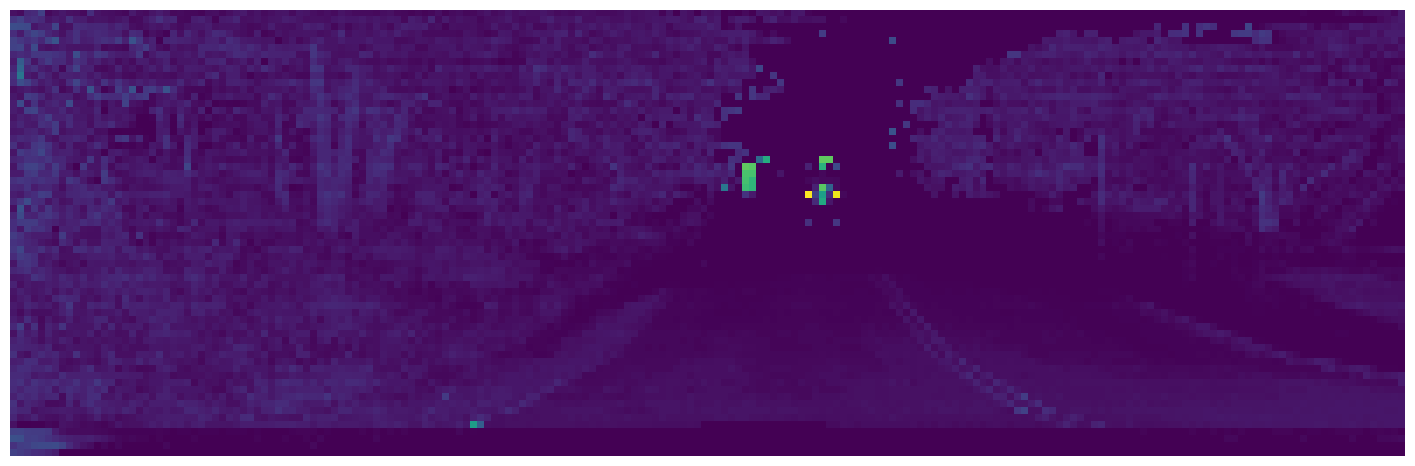

In [7]:
image = ImageData(image_filename, img_calib_file)
pointcloud = PointCloud(lidar_filename, lidar_calib_file)

destag_points, _, _ = pointcloud.destagger()


plt.figure(figsize=(18,30))
plt.imshow(destag_points[:,3].reshape(64, 1024)[:,400:600])
plt.axis('off')